# **Assignment 3**


## Preamble

- Loading Packages
- Generating Utilities

In [1]:
%matplotlib inline
import csv
import matplotlib.pyplot as plt
import numpy as np
import scipy

from abc import ABC
from itertools import product
from tqdm.notebook import tqdm
from typing import Optional, List, Tuple, Union, Dict

In [2]:
def squared_error(Y_pred: np.array, Y: np.array) -> np.ndarray:
    """ Computes the squared error. """
    if Y.ndim == 1:
        Y = Y[:, None]
    return np.sum(Y_pred - Y, axis=-1) ** 2

def accuracy(Y_pred: np.array, Y: np.array) -> np.ndarray:
    """ Computes the accuracy. """
    return Y_pred == Y

def compute_student_t_ci(n, err, axis=None):
    # alpha = 0.05
    mean_err = np.mean(err, axis=axis)
    std_err = np.std(err, axis=axis)
    ci = scipy.stats.t.ppf(0.975, df=n-1) * std_err / np.sqrt(n)
    return (mean_err - ci, mean_err + ci)

def compute_wilson_ci(n, acc, axis=None):
    # alpha = 0.05
    acc = np.mean(acc, axis=axis)
    base = (n * acc + 0.5 * 3.841) / (n + 3.841)
    err = np.sqrt(3.841) / (n + 3.841) * np.sqrt(n * acc * (1 - acc) + 0.25 * 3.841)

    return (base - err, base + err)

def load_mnist(path: str) -> Tuple[np.ndarray, np.ndarray]:
    data = []
    reader = csv.reader(open(path, "r"), delimiter=",")
    for row in reader:
        data.append([
            float(col) for col in row
        ])
    data = np.asarray(data)
    X = data[:, :-1].astype(float) / 255.0
    y = data[:, -1:].astype(int)

    return X, y

## Models as computational graphs
Recall that the backpropagation algorithm involves a forward pass and a backward pass in order to compute the gradient.
To achieve this seamlessly, modern deep-learning libraries represent these models using **computational graph**.
A computational graph is a directed graph where the nodes correspond to operations, e.g., sum/product/activation/loss, or variables, e.g., inputs, parameters, random variables.
Each directed edge represents values passing from the source node to the target node, e.g., in linear regression the output of a linear function $f(\mathbf{x}) = \mathbf{x} \mathbf{W}$ is passed to the squared-loss function $\ell (\hat{\mathbf{y}}, \mathbf{y})$, hence there will be an edge between the nodes of $f$ and $\ell$.

Here, the nodes will be in total ordering, i.e., suppose we have $v_1, \dots, v_n$ nodes in the computational graph.
A total ordering of $v_1, \dots, v_n$ is such that $\forall i < j, v_i$ is not a child of $v_j$.
Following the total ordering, we can run backpropagation as follows:
1. During the forward pass, we simply assign values to each variable, i.e., source nodes, and perform the operations, i.e. intermediate nodes, following the edges, until all nodes have populated their values.
2. During the backward pass, we start from the last populated node and compute the gradients in reverse total ordering.

Now, to implement this, we have already provided the necessary classes.
The general abstract class, `ComputationGraph` represents an operation, implementing the `forward` and `backward` methods for both forward and backward passes.
There are subclasses such as `Activation`, `Loss`, `Layer`, and `Model` that correspond to specific operations.
To represent the parameters variable we have a separate `Parameter` class that contains the parameter value (`data` attribute) and some gradient w.r.t. said parameter (`grad` attribute).
After creating a `Model`, you can access its parameters through the `parameters()` or `named_parameters()` methods.
To update the model's parameters, we use `Optimizer` to perform variants of gradient descent through the `step()` method.
Unlike previous assignments, the optimizer, by default, accumulates the gradient for computational reasons, so you have to call `zero_grad()` to reset the `grad` for each parameter.

This design resembles PyTorch, a commonly-used deep-learning package---ideally when you switch to PyTorch the transition is smoother and you have a better understanding of how it works underneath!

In [3]:
class Parameter:
    """
    A data structure to keep track of both the parameter data and gradient.
    NOTE: Ideally this should also implement primitive operations such as addition and matmul.
    """
    def __init__(self, data: np.ndarray):
        self.data = data
        self.grad = np.zeros_like(data)

    def __repr__(self):
        return str(self.data)

class ComputationGraph(ABC):
    def forward(self, x: np.ndarray) -> Union[np.ndarray, Dict]:
        raise NotImplementedError
    
    def backward(self, grad: Union[np.ndarray, Dict]) -> Union[np.ndarray, Dict]:
        raise NotImplementedError

### Activation
To start, you will implement the `Sigmoid` activation as computational graphs.
The `forward` method performs $\sigma(z)$ and the `backward` method performs the gradient computation $\frac{\partial f}{\partial \sigma(z)} \frac{\partial \sigma(z)}{\partial z}$, where $\frac{\partial f}{\partial \sigma(z)}$, provided as an argument `grad` in the `backward` method, is the gradient of some downstream function $f$ w.r.t. $\sigma(z)$.

When $\sigma(z) = \mathrm{sigmoid}(z)$, the gradient is
$$
\frac{\partial \sigma(z)}{\partial z} = \sigma(z) (1 - \sigma(z)).
$$

Implementation-wise, you will have to keep track of some computation during the forward call in order to compute the gradient---you may use `self.forward_data` to do so.

In [4]:
class Activation(ComputationGraph):
    pass
    
class Identity(Activation):
    """ Identity activation. """
    def forward(self, x: np.ndarray) -> np.ndarray:
        return x
    
    def backward(self, grad: np.ndarray) -> np.ndarray:
        return grad

class ReLU(Activation):
    """ ReLU activation. """
    forward_data: np.ndarray

    def forward(self, x: np.ndarray) -> np.ndarray:
        self.forward_data = (x > 0).astype(float)
        out = x * self.forward_data
        return out
    
    def backward(self, grad: np.ndarray) -> np.ndarray:
        G = grad * self.forward_data
        return G

class Sigmoid(Activation):
    """ Sigmoid activation. """
    forward_data: np.ndarray

    def forward(self, x):
        out = None
        ### BEGIN SOLUTION
        self.forward_data = 1 / (1 + np.exp(-x))
        out = self.forward_data
        ### END SOLUTION
        return out
    
    def backward(self, grad):
        G = None
        ### BEGIN SOLUTION
        G = grad * self.forward_data * (1 - self.forward_data)
        ### END SOLUTION
        return G

In [5]:
print("== Testing sigmoid ==")
def test_sigmoid():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    z = rng.standard_normal((n, d))

    sigmoid = Sigmoid()
    out = sigmoid.forward(z)
    expected_out = 1 / (1 + np.exp(-z))

    child_grad = np.arange(n * d).reshape((n, d)).astype(float) / (n * d)
    grad = sigmoid.backward(child_grad)
    expected_grad = child_grad * (1 / (1 + np.exp(-z))) * (1 - 1 / (1 + np.exp(-z)))

    assert np.allclose(expected_out, out)
    assert np.allclose(expected_grad, grad)

test_sigmoid()

print("✅ All sigmoid tests passed")


== Testing sigmoid ==
✅ All sigmoid tests passed


### Layer
A `Layer` represents some fundamental computation block, e.g. linear layer and convolutional layer.
Importantly a `Layer` should contain some sort of parameters.

In [6]:
class Layer(ComputationGraph):
    pass

def he_init(in_dim, out_dim, rng):
    return rng.standard_normal(size=(in_dim, out_dim)) * 2 / in_dim

class Linear(Layer):
    def __init__(self,
                 in_dim: int,
                 out_dim: int,
                 rng: np.random.RandomState,
                 with_bias=True,
                 initializer=he_init):
        self.W = Parameter(
            initializer(in_dim, out_dim, rng)
        )

        self.with_bias = with_bias
        if with_bias:
            self.b = Parameter(
                np.zeros((1, out_dim))
            )
    
    def forward(self, x: np.ndarray) -> np.ndarray:
        self.x = x
        return x @ self.W.data + (self.b.data if self.with_bias else 0)
    
    def backward(self, grad: np.ndarray) -> np.ndarray:
        # Accumulate gradient for optimizer step
        self.W.grad += self.x.T @ grad
        if self.with_bias:
            self.b.grad += np.sum(grad, axis=0, keepdims=True)

        # Return the gradient
        return grad @ self.W.data.T

    def parameters(self) -> List[Parameter]:
        return [self.W, self.b] if self.with_bias else [self.W]
    
    def named_parameters(self, prefix="") -> Dict[str, Parameter]:
        return {
            f"{prefix}W": self.W,
            f"{prefix}b": self.b,
        } if self.with_bias else {
            f"{prefix}W": self.W,
        }

class ModuleList(Layer):
    def __init__(self,
                 layers: List[Layer]):
        self.layers = layers

    def forward(self, x: np.ndarray) -> np.ndarray:
        for layer in self.layers:
            x = layer.forward(x)
        return x
    
    def backward(self, grad: np.ndarray) -> np.ndarray:
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad
    
    def parameters(self) -> List[Parameter]:
        params = []
        for layer in self.layers:
            if isinstance(layer, Layer):
                params.extend(layer.parameters())
        return params

    def named_parameters(self, prefix: str="") -> Dict[str, Parameter]:
        named_params = {}
        for idx, layer in enumerate(self.layers):
            if isinstance(layer, Layer):
                layer_params = layer.named_parameters()
                for name, param in layer_params.items():
                    named_params[f"{prefix}layer.{idx}_{name}"] = param
        return named_params

### Model
A `Model` is a function applying a composition of one or more `Layer`.
It requires the `forward` method to output a dictionary of NumPy arrays---this design enables models that has potentially multi-modal outputs, e.g., supervised autoencoder.

In [7]:
class Model(ComputationGraph):
    def parameters(self) -> List[Parameter]:
        raise NotImplementedError

    def named_parameters(self, prefix: str="") -> Dict[str, Parameter]:
        raise NotImplementedError

class MLP(Model):
    def __init__(self,
                 in_dim: int,
                 out_dim: int,
                 hidden_dims: List[int],
                 activation_cls: callable,
                 rng: np.random.RandomState):
        layer_sizes = [in_dim] + hidden_dims + [out_dim]
        layers = []
        for i in range(len(layer_sizes) - 1):
            layers.append(Linear(layer_sizes[i], layer_sizes[i+1], rng))
            if i < len(layer_sizes) - 2:
                layers.append(activation_cls())
        self.mlp = ModuleList(layers)
    
    def forward(self, x: np.ndarray) -> Dict[str, np.ndarray]:
        return {
            "prediction": self.mlp.forward(x),
        }
    
    def backward(self, grad: np.ndarray) -> np.ndarray:
        return self.mlp.backward(grad)
    
    def parameters(self) -> List[Parameter]:
        return self.mlp.parameters()
    
    def named_parameters(self, prefix: str="") -> Dict[str, Parameter]:
        return self.mlp.named_parameters("{}mlp.".format(prefix))


### Loss
A `Loss` is usually a leaf node in a computation graph---in this assignment we'll assume that it's always a leaf.
Consequently its `backward` method takes no arguments.

In [8]:
class Loss(ComputationGraph):
    def backward(self) -> Union[np.ndarray, Dict]:
        raise NotImplementedError

class SquaredLoss(Loss):
    def forward(self, predictions: np.ndarray, targets: np.ndarray) -> np.ndarray:
        self.predictions = predictions
        self.targets = targets
        return 0.5 * np.mean((predictions - targets) ** 2)
    
    def backward(self) -> np.ndarray:
        return (self.predictions - self.targets) / self.targets.shape[0]
    
class BinaryCrossEntropyLossWithLogits(Loss):
    def forward(self, predictions: np.ndarray, targets: np.ndarray) -> np.ndarray:
        # Treats each entry of the predictions as class 1 logits
        self.predictions = predictions
        self.targets = targets

        self.max_val = np.clip(-predictions, a_min=0, a_max=np.inf)
        loss = np.mean(
            self.predictions
            - self.predictions * targets
            + self.max_val
            + np.log(np.exp(-self.max_val) + np.exp(-self.predictions - self.max_val))
        )

        return loss
    
    def backward(self) -> np.ndarray:
        return (
            1
            - self.targets
            + (
                -np.exp(-self.predictions - self.max_val)
                / (np.exp(-self.max_val) + np.exp(-self.predictions - self.max_val))
            )
        ) / self.targets.shape[0]

class CrossEntropyLossWithLogits(Loss):
    def forward(self, logits: np.ndarray, targets: np.ndarray) -> np.ndarray:
        self.batch_size = logits.shape[0]
        logits = logits.reshape(-1, logits.shape[-1])
        targets = targets.flatten()
        self.logits = logits
        self.targets = targets
        exps = np.exp(logits - np.max(logits, axis=1, keepdims=True))
        softmax = exps / np.sum(exps, axis=1, keepdims=True)
        self.softmax = softmax
        log_likelihood = -np.log(softmax[range(self.batch_size), targets])
        loss = np.sum(log_likelihood) / self.batch_size
        return loss
    
    def backward(self) -> np.ndarray:
        grad = self.softmax.copy()
        grad[range(self.batch_size), self.targets] -= 1
        grad /= self.batch_size
        return grad

### Optimizer

In [9]:
class Optimizer(ABC):
    def __init__(self, parameters: List[Parameter]):
        self.parameters = parameters

    def step(self):
        raise NotImplementedError
    
    def zero_grad(self):
        for param in self.parameters:
            param.grad.fill(0)

class SGD(Optimizer):
    def __init__(self, parameters: List[Parameter], lr: float=0.01):
        super().__init__(parameters)
        self.lr = lr
    
    def step(self):
        for param in self.parameters:
            param.data -= self.lr * param.grad

class Adam(Optimizer):
    def __init__(self,
                 parameters: List[Parameter],
                 lr: float = 1e-3,
                 beta1: float = 0.9,
                 beta2: float = 0.999,
                 eps: float = 1e-8):
        super().__init__(parameters)
        self.lr = float(lr)
        self.beta1 = float(beta1)
        self.beta2 = float(beta2)
        self.eps = float(eps)
        self.M: Optional[np.ndarray] = [np.zeros_like(p.data) for p in self.parameters]
        self.V: Optional[np.ndarray] = [np.zeros_like(p.data) for p in self.parameters]
        self.t = 0

    def step(self):
        self.t += 1

        for idx, param in enumerate(self.parameters):
            # First moment (EMA of gradients)
            self.M[idx] = self.beta1 * self.M[idx] + (1 - self.beta1) * param.grad
            # Second moment (EMA of squared grads)
            self.V[idx] = self.beta2 * self.V[idx] + (1 - self.beta2) * (param.grad * param.grad)
            M_hat = self.M[idx] / (1 - self.beta1 ** self.t)
            V_hat = self.V[idx] / (1 - self.beta2 ** self.t)
            param.data -= self.lr * M_hat / (np.sqrt(V_hat) + self.eps)

class AdamL1(Optimizer):
    def __init__(self,
                 parameters: List[Parameter],
                 lr: float = 1e-3,
                 beta1: float = 0.9,
                 beta2: float = 0.999,
                 eps: float = 1e-8,
                 lambda_: float = 0.0,):
        super().__init__(parameters)
        self.lr = float(lr)
        self.beta1 = float(beta1)
        self.beta2 = float(beta2)
        self.eps = float(eps)
        self.M: Optional[np.ndarray] = [np.zeros_like(p.data) for p in self.parameters]
        self.V: Optional[np.ndarray] = [np.zeros_like(p.data) for p in self.parameters]
        self.t = 0
        self.lambda_ = lambda_

    def step(self):
        self.t += 1

        for idx, param in enumerate(self.parameters):
            # First moment (EMA of gradients)
            self.M[idx] = self.beta1 * self.M[idx] + (1 - self.beta1) * param.grad
            # Second moment (EMA of squared grads)
            self.V[idx] = self.beta2 * self.V[idx] + (1 - self.beta2) * (param.grad * param.grad)
            M_hat = self.M[idx] / (1 - self.beta1 ** self.t)
            V_hat = self.V[idx] / (1 - self.beta2 ** self.t)
            param.data -= self.lr * (M_hat / (np.sqrt(V_hat) + self.eps) + self.lambda_ * np.sign(param.data))

### Trainer

In [10]:
class Trainer:
    """
    Mini-batch training loop that logs per epoch (optionally on a validation set).

    Args:
        model (Model): The particular model to use.
        optimizer (Optimizer): The optimizer to use.
        metric (callable): The metric to use to keep track of model performance.
        epochs (int): Number of epochs to train.
        batch_size (int): Number of samples per mini-batch.
        shuffle (bool): Whether to shuffle the data.
        seed (int): Random seed.
    """
    def __init__(self,
                 model: Model,
                 optimizer: Optimizer,
                 update_rule: callable,
                 metric: callable,
                 epochs: int = 100,
                 batch_size: int = 32,
                 shuffle: bool = True,
                 seed: int = 0):
        self.model = model
        self.optimizer = optimizer
        self.update_rule = update_rule
        self.metric = metric
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.seed = int(seed)
        self.history = {
            "train_metric": [],
            "val_metric": [],
            "logs": {},
        } # Per-epoch metrics for plotting

    def fit(self,
            X: np.ndarray,
            Y: np.ndarray,
            X_val: Optional[np.ndarray] = None,
            Y_val: Optional[np.ndarray] = None):
        rng = np.random.default_rng(self.seed)
        n = len(Y)
        B = self.batch_size
        for _ in range(self.epochs):
            # Shuffle once per epoch
            idx = rng.permutation(n) if self.shuffle else np.arange(n)

            curr_log = dict()
            # Iterate over mini-batches
            for s in range(0, n, B):
                batch_idx = idx[s:s+B]
                Xb, Yb = X[batch_idx], Y[batch_idx]
                logs = self.update_rule(self.model, self.optimizer, Xb, Yb)

                for k, v in logs.items():
                    curr_log.setdefault(k, [])
                    curr_log[k].append(v)

            for k, v in curr_log.items():
                self.history["logs"].setdefault(k, [])
                self.history["logs"][k].append(np.mean(v))

            # Track training metric (and validation) after the epoch
            train_metric = self.metric(self.model.forward(X), Y, X)
            self.history["train_metric"].append(train_metric)
            if X_val is not None and Y_val is not None:
                val_metric = self.metric(self.model.forward(X_val), Y_val, X_val)
                self.history["val_metric"].append(val_metric)
        return self


## Skip connection
Let's now implement your first `Layer`.
In this section you will implement skip connection which often improves learning dyanmics.
Let $\mathbf{X} \in \mathbb{R}^{n \times d}$ be an input.
A skip connection layer, $\mathbf{SC}$, is parameterized by two weight matrices, $\mathbf{W}_1, \mathbf{W}_2 \in \mathbb{R}^{d \times d}$, and is defined as:
$$
\mathrm{SC}(\mathbf{X}; \mathbf{W}_1, \mathbf{W}_2) = \sigma(\mathbf{X} \mathbf{W}_1)\mathbf{W}_2 + \mathbf{X}.
$$

Complete both the `forward` and `backward` methods.

In [11]:
class SkipConnection(Layer):
    def __init__(self,
                 in_dim: int,
                 activation_cls: callable,
                 rng: np.random.RandomState):
        layers = [
            Linear(in_dim, in_dim, rng),
            activation_cls(),
            Linear(in_dim, in_dim, rng),
        ]
        self.skip_connection = ModuleList(layers)
    
    def forward(self, x: np.ndarray) -> Dict[str, np.ndarray]:
        """
        The forward call of a skip connection layer.

        Args:
            x (np.ndarray): The model input
        """
        out = None
        ### BEGIN SOLUTION
        # out = self.skip_connection.layers[2].forward(self.skip_connection.layers[1].forward(self.skip_connection.layers[0].forward(x))) + x
        out = self.skip_connection.forward(x) + x
        ### END SOLUTION
        return out
    
    def backward(self, grad: np.ndarray) -> np.ndarray:
        """
        The backward call of a skip connection layer.

        Args:
            grad (np.ndarray): The gradient of its child.
        """
        out_grad = None
        ### BEGIN SOLUTION
        # (dF / dx) + I
        grad_through_layers = self.skip_connection.backward(grad)
    
        # Add gradient from identity skip path
        out_grad = grad_through_layers + grad
    
        ### END SOLUTION
        return out_grad
    
    def parameters(self) -> List[Parameter]:
        return self.skip_connection.parameters()
    
    def named_parameters(self, prefix: str="") -> Dict[str, Parameter]:
        return self.skip_connection.named_parameters("{}skip_connection.".format(prefix))

class MLPWithSkipConnection(Model):
    def __init__(self,
                 in_dim: int,
                 out_dim: int,
                 hidden_dims: List[int],
                 activation_cls: callable,
                 rng: np.random.RandomState):
        layer_sizes = [in_dim] + hidden_dims + [out_dim]
        layers = []
        layers.append(Linear(layer_sizes[0], layer_sizes[1], rng))
        if len(layer_sizes) > 2:
            layers.append(activation_cls())
        for i in range(1, len(layer_sizes) - 1):
            layers.append(SkipConnection(layer_sizes[i], activation_cls, rng))
            layers.append(activation_cls())
            layers.append(Linear(layer_sizes[i], layer_sizes[i+1], rng))
            if i < len(layer_sizes) - 2:
                layers.append(activation_cls())
        self.mlp = ModuleList(layers)
    
    def forward(self, x: np.ndarray) -> Dict[str, np.ndarray]:
        return {
            "prediction": self.mlp.forward(x),
        }
    
    def backward(self, grad: np.ndarray) -> np.ndarray:
        return self.mlp.backward(grad)
    
    def parameters(self) -> List[Parameter]:
        return self.mlp.parameters()
    
    def named_parameters(self, prefix: str="") -> Dict[str, Parameter]:
        return self.mlp.named_parameters("{}skip_connection_mlp.".format(prefix))

In [12]:
print("== Testing skip connection ==")
def test_skip_connection_forward():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    X = rng.standard_normal((n, d))

    skip_connection = SkipConnection(d, Identity, rng)

    expected_out = X[:]
    for layer_name, param in skip_connection.named_parameters().items():
        if layer_name.endswith("W"):
            expected_out = expected_out @ param.data
        elif layer_name.endswith("b"):
            expected_out = expected_out + param.data
    expected_out = expected_out + X

    out = skip_connection.forward(X)
    assert np.allclose(expected_out, out)

def test_skip_connection_backward():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    X = rng.standard_normal((n, d))

    skip_connection = SkipConnection(d, Identity, rng)
    linear = Linear(d, 1, rng, False)
    out = skip_connection.forward(X)
    preds = linear.forward(out)
    loss = SquaredLoss()
    loss.forward(preds, np.zeros_like(preds))
    grads = loss.backward()
    grads = linear.backward(grads)
    out = skip_connection.backward(grads)
    expected_out = skip_connection.skip_connection.backward(grads) + grads
        
    assert np.allclose(expected_out, out)

test_skip_connection_forward()
test_skip_connection_backward()

print("✅ All skip connection tests passed")


== Testing skip connection ==
✅ All skip connection tests passed


#### Alleviate vanishing gradient with skip connection

In [13]:
grad_threshold = 1e-7
def make_supervised_update_rule(pred_loss: Loss):
    def supervised_update_rule(model: Model,
                               optimizer: Optimizer,
                               Xb: np.ndarray,
                               Yb: np.ndarray,):
        optimizer.zero_grad()
        predictions = model.forward(Xb)["prediction"]
        loss = pred_loss.forward(predictions, Yb)
        grad = pred_loss.backward()
        model.backward(grad)
        optimizer.step()

        vanishing_grads = np.sum([
            [np.sum(np.abs(param.grad) <= grad_threshold), int(np.prod(param.grad.shape))]
            for param in model.parameters()
        ], axis=0)
        logs = {
            "% vanishing gradient": vanishing_grads[0] / vanishing_grads[1],
        }
        return logs
    return supervised_update_rule

In [14]:
seed = 42
n = 50
in_dim = 10
out_dim = 1
data_rng = np.random.RandomState(seed)
x = data_rng.randn(n, in_dim)
w = data_rng.randn(in_dim, out_dim)
y = x @ w + data_rng.randn(n, out_dim) * 1.0

num_runs = 100

In [15]:
vanishing_grads = []
train_losses = []
for run_i in range(num_runs):
    model = MLP(in_dim=in_dim,
                out_dim=out_dim,
                hidden_dims=[in_dim, 5, 5, 5, 10, 10],
                activation_cls=ReLU,
                rng=np.random.default_rng(seed + run_i))

    opt = SGD(parameters=model.parameters(), lr=0.1)

    trainer = Trainer(
        model=model,
        optimizer=opt,
        update_rule=make_supervised_update_rule(pred_loss=SquaredLoss()),
        metric=lambda preds, targets, *args: squared_error(preds["prediction"], targets),
        epochs=100,
        batch_size=50,
    ).fit(x, y)

    vanishing_grads.append(trainer.history["logs"]["% vanishing gradient"])
    train_losses.append(np.mean(trainer.history["train_metric"], axis=-1))

In [16]:
sc_vanishing_grads = []
sc_train_losses = []
for run_i in range(num_runs):
    model = MLPWithSkipConnection(in_dim=in_dim,
                                  out_dim=out_dim,
                                  hidden_dims=[5, 10],
                                  activation_cls=ReLU,
                                  rng=np.random.default_rng(seed + run_i))

    opt = SGD(parameters=model.parameters(), lr=0.1)

    trainer = Trainer(
        model=model,
        optimizer=opt,
        update_rule=make_supervised_update_rule(pred_loss=SquaredLoss()),
        metric=lambda preds, targets, *args: squared_error(preds["prediction"], targets),
        epochs=100,
        batch_size=50,
    ).fit(x, y)

    sc_vanishing_grads.append(trainer.history["logs"]["% vanishing gradient"])
    sc_train_losses.append(np.mean(trainer.history["train_metric"], axis=-1))

In [17]:
def plot_sc_exp(scores: Dict[str, np.ndarray]):

    num_rows = 1
    num_cols = 2
    fig, axes = plt.subplots(num_rows, num_cols, layout="constrained", figsize=(5.0 * num_cols, 5.0 * num_rows))
    for key, test_score in scores.items():
        sample_mean = np.mean(test_score[0], axis=0)
        ci = compute_wilson_ci(num_runs, test_score[0], axis=0)
        axes[0].plot(
            np.arange(test_score[0].shape[1]),
            sample_mean,
            label=key
        )
        axes[0].fill_between(
            np.arange(test_score[0].shape[1]),
            ci[0],
            ci[1],
            alpha=0.3,
        )

        axes[1].plot(
            np.arange(test_score[1].shape[1]),
            np.mean(test_score[1], axis=0),
        )
        cis = compute_student_t_ci(num_runs, test_score[1], axis=0)
        axes[1].fill_between(
            np.arange(test_score[1].shape[1]),
            cis[0],
            cis[1],
            alpha=0.3,
        )

    axes[0].set_ylabel("% vanishing gradient")
    axes[0].set_title("% vanishing gradient over training")
    axes[1].set_ylabel("MSE")
    axes[1].set_title("Training loss")
    
    fig.supxlabel("Epochs")
    fig.legend(
        bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
        loc="lower center",
        ncols=4,
        borderaxespad=0.0,
        frameon=True,
        fontsize="8",
    )
    fig.suptitle("Model comparison over {} runs".format(num_runs))
    plt.savefig("figure1.png")
    plt.show()

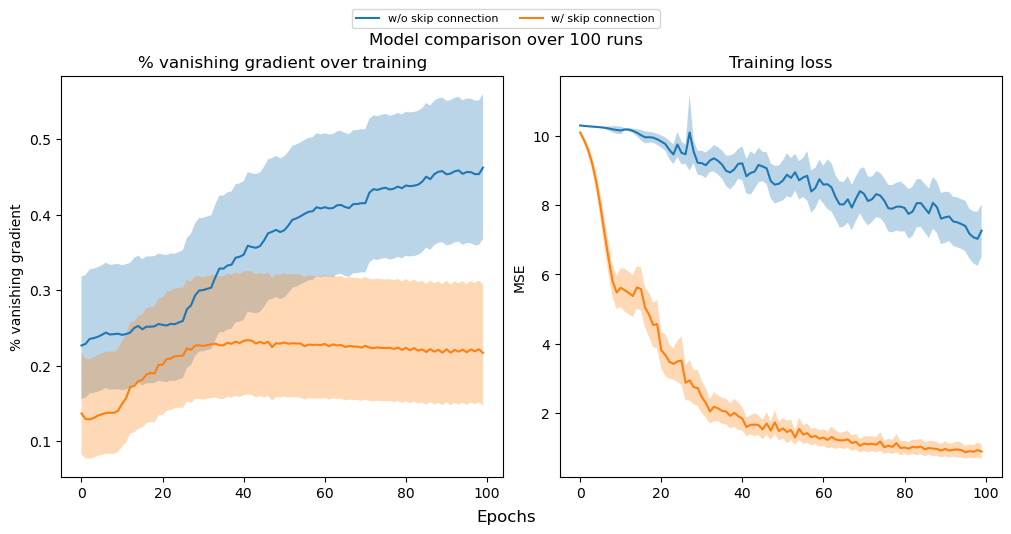

In [18]:
plot_sc_exp({
    "w/o skip connection": [np.array(vanishing_grads), np.array(train_losses)],
    "w/ skip connection": [np.array(sc_vanishing_grads), np.array(sc_train_losses)],
})

## Supervised autoencoder
In the notes, a supervised autoencoder (SAE) is an MLP with a single hidden layer without activation, and we optimize the SAE parameters through minimizing a joint loss function:
$$
\ell(\mathbf{x}, \mathbf{y}; \mathbf{W}^{(2)}, \mathbf{W}_x^{(1)}, \mathbf{W}_y^{(1)}) = \ell_y(\hat{\mathbf{y}}, \mathbf{y}) + \beta \ell_x(\hat{\mathbf{x}}, \mathbf{x}),
$$
where $\ell_y$ is the prediction loss and $\ell_x$ is the reconstruction loss, with $\beta \geq 0$ being the strength of the reconstruction loss.
In particular, we have
$$
\begin{align*}
    \ell_x(\hat{\mathbf{x}}, \mathbf{x}) &= \frac{1}{2} \| \mathbf{x} \mathbf{W}^{(2)} \mathbf{W}^{(1)}_x - \mathbf{x} \|^2_2 \\
    \ell_y(\hat{\mathbf{y}}, \mathbf{y}) &= \ln (\exp(\mathbf{x}_i \mathbf{W}^{(2)} \mathbf{W}^{(1)}_y) \mathbf{1}) - \mathbf{x}_i \mathbf{W}^{(2)} \mathbf{W}^{(1)}_y \mathbf{y}^\top
\end{align*}
$$

In general, these models can be any architecture, e.g. MLP, CNN, MLP with skip connection, etc., so long as they comply with their corresponding input/output dimensionalities.
Replacing $\mathbf{W}^{(2)}, \mathbf{W}^{(1)}_x, \mathbf{W}^{(1)}_y$ with $E, D_x, D_y$, respectively corresponding to encoder, decoder, and predictor, we can now write:
$$
\begin{align*}
    \ell_x(\hat{\mathbf{x}}, \mathbf{x}) &= \frac{1}{2} \| D_x(E(\mathbf{x})) - \mathbf{x} \|^2_2 \\
    \ell_y(\hat{\mathbf{y}}, \mathbf{y}) &= \ln (\exp(D_y(E(\mathbf{x})) \mathbf{1}) - D_y(E(\mathbf{x})) \mathbf{y}^\top
\end{align*}
$$
We can further generalize both the reconstruction and prediction losses, e.g. using various transfer functions.

In this part of the notebook, you will implement the (more general) supervised autoencoder (SAE).
1. The autoencoder here takes in a `Model` for each of `encoder`, `decoder`, and `predictor`. Complete the `forward` and `backward` methods in the `SupervisedAutoencoder` class.
2. Complete the `forward` and `backward` methods in the `SAELoss` class.
3. Complete `make_sae_update_rule` function to implement the proper SAE update rule---here the update rule will perform the forward and backward passes and update the parameters of the SAE model.

In [19]:
class SupervisedAutoencoder(Model):
    def __init__(self,
                 encoder: Model,
                 decoder: Model,
                 predictor: Model):
        """
        Supervised autoencoder

        Args:
            encoder (np.ndarray): The encoder.
            decoder (np.ndarray): The decoder for reconstruction.
            predictor (np.ndarray): The predictor for prediction.
        """
        self.encoder = encoder
        self.decoder = decoder
        self.predictor = predictor
    
    def forward(self, x: np.ndarray) -> Dict[str, np.ndarray]:
        """
        The forward call of the SAE.
        Here, self.encoder, self.decoder, and self.predictor all output a dictionary when their forward methods are called:
        {
            "prediction": np.ndarray,
        }
        You may use them to construct the SAE's output.

        Args:
            x (np.ndarray): The model input
        """
        reconstructed = None
        predictions = None
        ### BEGIN SOLUTION
        encoded = self.encoder.forward(x)["prediction"]
        reconstructed = self.decoder.forward(encoded)["prediction"]
        predictions = self.predictor.forward(encoded)["prediction"]
        ### END SOLUTION
        return {
            "reconstruction": reconstructed,
            "prediction": predictions,
        }
    
    def backward(self, grad: Dict[str, np.ndarray]) -> np.ndarray:
        """
        The backward call of a SAE.

        Here, you may assume that grad is a dictionary:
        {
            "prediction": np.ndarray,
            "reconstruction": np.ndarray,
        }
        You may use them to compute the gradient w.r.t. the SAE's parameters.

        Args:
            grad (Dict[str, np.ndarray]): The gradient of its children,
                                          i.e., from the reconstruction loss and the prediction loss.
        """
        out_grad = None
        ### BEGIN SOLUTION
        rec_grad = self.decoder.backward(grad["reconstruction"])
        pre_grad = self.predictor.backward(grad["prediction"])
        out_grad = self.encoder.backward(rec_grad + pre_grad)
        ### END SOLUTION
        return out_grad

    def parameters(self) -> List[Parameter]:
        params = []
        for layer in [self.encoder, self.decoder, self.predictor]:
            params.extend(layer.parameters())
        return params
    
    def named_parameters(self) -> Dict[str, Parameter]:
        named_params = {}
        for name, layer in zip(
            ["encoder", "decoder", "predictor"],
            [self.encoder, self.decoder, self.predictor],
        ):
            layer_params = layer.named_parameters(prefix=f"{name}.")
            named_params.update(layer_params)
        return named_params

In [20]:
print("== Testing supervised autoencoder ==")
def test_sae_forward():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    h = 8
    m = 2
    X = rng.standard_normal((n, d))

    sae = SupervisedAutoencoder(
        MLP(d, h, [], Identity, rng),
        MLP(h, d, [], Identity, rng),
        MLP(h, m, [], Identity, rng),
    )

    latent = sae.encoder.forward(X)["prediction"]
    expected_pred = sae.predictor.forward(latent)["prediction"]
    expected_recon = sae.decoder.forward(latent)["prediction"]

    out = sae.forward(X)
    assert "prediction" in out
    assert "reconstruction" in out
    assert np.allclose(expected_pred, out["prediction"])
    assert np.allclose(expected_recon, out["reconstruction"])

def test_sae_backward():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    h = 8
    m = 2
    X = rng.standard_normal((n, d))

    encoder = MLP(d, h, [], Identity, rng)
    decoder = MLP(h, d, [], Identity, rng)
    predictor = MLP(h, m, [], Identity, rng)
    sae = SupervisedAutoencoder(
        encoder,
        decoder,
        predictor,
    )
    sae.forward(X)

    recon_grads = np.ones((n, d))
    pred_grads = np.ones((n, m))

    grads = sae.backward({
        "prediction": pred_grads,
        "reconstruction": recon_grads,
    })

    latent = encoder.forward(X)["prediction"]
    predictor.forward(latent)
    decoder.forward(latent)
    expected_grads = encoder.backward(
        predictor.backward(pred_grads) + decoder.backward(recon_grads)
    )

    assert np.allclose(expected_grads, grads)

test_sae_forward()
test_sae_backward()

print("✅ All supervised autoencoder tests passed")


== Testing supervised autoencoder ==
✅ All supervised autoencoder tests passed


In [21]:
class SAELoss(Loss):
    def __init__(self, beta: float, pred_loss: Loss, recon_loss: Loss):
        """
        Loss for supervised autoencoder

        Args:
            beta (float): The weight of the reconstruction loss.
            pred_loss (Loss): The prediction loss to use.
            recon_loss (Loss): The reconstruction loss to use.
        """
        self.beta = beta
        self.pred_loss = pred_loss
        self.recon_loss = recon_loss
    
    def forward(self,
                reconstructions: np.ndarray,
                inputs: np.ndarray,
                predictions: np.ndarray,
                targets: np.ndarray) -> np.ndarray:
        """
        The forward call of the SAE loss.

        Args:
            reconstructions (np.ndarray): The model reconstructed input
            inputs (np.ndarray): The training input
            predictions (np.ndarray): The model prediction
            targets (np.ndarray): The training target
        """
        total_loss = None
        ### BEGIN SOLUTION
        lx = self.recon_loss.forward(reconstructions, inputs)
        ly = self.pred_loss.forward(predictions, targets)
        total_loss = ly + self.beta * lx
        ### END SOLUTION
        return total_loss
    
    def backward(self) -> Dict[str, np.ndarray]:
        """
        The backward call of the SAE loss.

        Here, you may assume that output gradient is a dictionary:
        {
            "prediction": np.ndarray,
            "reconstruction": np.ndarray,
        }

        Args:
            grad (Dict[str, np.ndarray]): The gradient of the SAE loss w.r.t. its inputs.
        """
        recon_grad = None
        pred_grad = None
        ### BEGIN SOLUTION
        recon_grad = self.beta * self.recon_loss.backward()
        pred_grad = self.pred_loss.backward()
        ### END SOLUTION
        return {
            "reconstruction": recon_grad,
            "prediction": pred_grad,
        }

In [22]:
print("== Testing SAE loss ==")
def test_sae_loss_forward():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    h = 8
    m = 2
    X = rng.standard_normal((n, d))
    recon_X = X + rng.standard_normal((n, d)) * 0.01
    w_true = rng.standard_normal((d, 1))
    y = X @ w_true
    pred = recon_X @ w_true

    beta = 0.1
    pred_loss = SquaredLoss()
    recon_loss = SquaredLoss()

    loss = SAELoss(
        beta,
        pred_loss,
        recon_loss,
    )

    out_loss = loss.forward(
        recon_X,
        X,
        pred,
        y,
    )

    expected_loss = pred_loss.forward(pred, y) + beta * recon_loss.forward(recon_X, X)

    assert np.allclose(out_loss, expected_loss)

def test_sae_loss_backward():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    m = 2
    X = rng.standard_normal((n, d))
    recon_X = X + rng.standard_normal((n, d)) * 0.01
    w_true = rng.standard_normal((d, m))
    y = rng.integers(0, 2, size=(n,)).astype(int)
    pred = recon_X @ w_true

    beta = 0.1
    pred_loss = CrossEntropyLossWithLogits()
    recon_loss = SquaredLoss()

    loss = SAELoss(
        beta,
        CrossEntropyLossWithLogits(),
        SquaredLoss(),
    )

    loss.forward(
        recon_X,
        X,
        pred,
        y,
    )
    grads = loss.backward()
    
    pred_loss.forward(pred, y)
    recon_loss.forward(recon_X, X)

    expected_grads = {
        "reconstruction": beta * recon_loss.backward(),
        "prediction": pred_loss.backward(),
    }

    assert np.allclose(expected_grads["reconstruction"], grads["reconstruction"])
    assert np.allclose(expected_grads["prediction"], grads["prediction"])

test_sae_loss_forward()
test_sae_loss_backward()

print("✅ All SAE loss tests passed")


== Testing SAE loss ==
✅ All SAE loss tests passed


In [23]:
def make_sae_update_rule(beta: float, pred_loss: Loss, recon_loss: Loss):
    def sae_update_rule(model: SupervisedAutoencoder,
                        optimizer: Optimizer,
                        Xb: np.ndarray,
                        Yb: np.ndarray,):
        """
        The update rule of SAE. This function orchestrates how to update the SAE parameters.

        NOTE: Call optimizer.zero_grad() to clear out the gradient of the parameters between each iteration.
        NOTE: optimizer.step() will perform gradient update after model.backward(grad).

        Args:
            model (SupervisedAutoencoder): The SAE model.
            optimizer (Optimizer): The optimizer to use.
            Xb (np.ndarray): Training inputs.
            Yb (np.ndarray): Training targets.
        """
        ### BEGIN SOLUTION
        # Compute the loss, compute its gradient w.r.t. parameters, and perform gradient update
        optimizer.zero_grad()
        output = model.forward(Xb)
        
        recon = output["reconstruction"]
        pred = output["prediction"]
        loss = SAELoss(beta, pred_loss, recon_loss,)
        
        loss.forward(recon, Xb, pred, Yb)
        grad = loss.backward()
        
        model.backward(grad)
        optimizer.step()
        ### END SOLUTION
        logs = {
            "grad_norm": np.mean([np.linalg.norm(param.grad) for param in model.parameters()]),
        }
        return logs
    return sae_update_rule

In [24]:
print("== Testing SAE update rule ==")
def test_sae_update_rule():
    rng = np.random.default_rng(0)

    n = 5
    d = 10
    h = 8
    m = 2
    X = rng.standard_normal((n, d))
    recon_X = X + rng.standard_normal((n, d)) * 0.01
    w_true = rng.standard_normal((d, 1))
    y = X @ w_true

    beta = 0.1
    pred_loss = SquaredLoss()
    recon_loss = SquaredLoss()

    loss = SAELoss(
        beta,
        pred_loss,
        recon_loss,
    )

    model = SupervisedAutoencoder(
        MLP(d, h, [], Identity, rng),
        MLP(h, d, [], Identity, rng),
        MLP(h, m, [], Identity, rng),
    )

    model_out = model.forward(X)

    loss.forward(
        model_out["reconstruction"],
        X,
        model_out["prediction"],
        y,
    )

    lr = 0.1
    grads = loss.backward()
    model.backward(grads)
    expected_grads = {k: np.copy(v.grad) for k, v in model.named_parameters().items()}
    expected_params = {k: v.data - lr * v.grad for k, v in model.named_parameters().items()}

    update_rule = make_sae_update_rule(beta, pred_loss, recon_loss)
    update_rule(
        model,
        SGD(model.parameters(), lr),
        X,
        y,
    )

    for k, v in model.named_parameters().items():
        assert np.allclose(v.grad, expected_grads[k]), "wrong gradient"
        assert np.allclose(v.data, expected_params[k]), "wrong parameter"

test_sae_update_rule()

print("✅ All SAE update rule tests passed")


== Testing SAE update rule ==
✅ All SAE update rule tests passed


## [MNIST](https://www.tensorflow.org/datasets/catalog/mnist) experiments
The MNIST dataset is a dataset of hand-written digits.
The inputs correspond to a flattened 28x28 (784 dimensions) grayscaled image, and the outputs correspond to digits from 0 to 9.
The original dataset consists of 60K samples, but here we only consider digits from 0 to 4 and take 5000/10000 samples for train/validation split.
We will be conducting multiple experiments to analyze various model architectures, sparsity, and loss functions.

In [25]:
seed = 42
num_samples = 5000
in_dim = 784
out_dim = 5

x_tr, y_tr = load_mnist("mnist_train.csv")
x_val, y_val = load_mnist("mnist_val.csv")

### Scaling experiment

  0%|          | 0/5 [00:00<?, ?it/s]

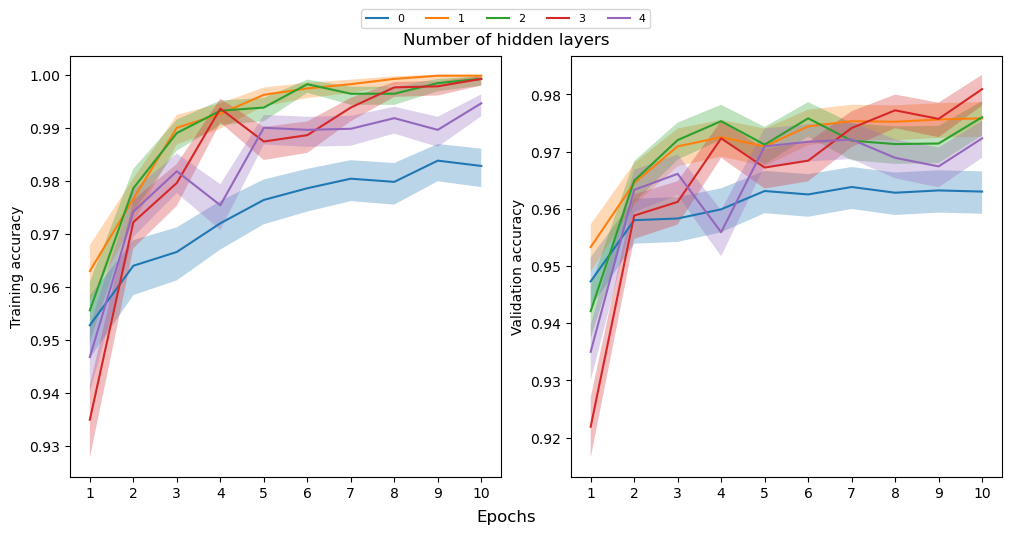

In [26]:
num_rows = 1
num_cols = 2
fig, axes = plt.subplots(num_rows, num_cols, layout="constrained", figsize=(5.0 * num_cols, 5.0 * num_rows))

hidden_dim = 128

for depth in tqdm([0, 1, 2, 3, 4]):
    model = MLP(
        in_dim=in_dim,
        out_dim=out_dim,
        hidden_dims=[hidden_dim] * depth,
        activation_cls=ReLU,
        rng=np.random.default_rng(seed),
    )
    opt = Adam(parameters=model.parameters(), lr=0.005)

    trainer = Trainer(
        model=model,
        optimizer=opt,
        update_rule=make_supervised_update_rule(
            pred_loss=CrossEntropyLossWithLogits(),
        ),
        metric=lambda preds, targets, *args: accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        epochs=10,
        batch_size=100,
    ).fit(x_tr, y_tr, x_val, y_val)

    metric = np.array(trainer.history["train_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[0].plot(
        x_range,
        np.mean(metric, axis=-1),
        label=depth
    )
    axes[0].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array(trainer.history["val_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[1].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[1].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

axes[0].set_xticks(x_range)
axes[0].set_ylabel("Training accuracy")
axes[1].set_xticks(x_range)
axes[1].set_ylabel("Validation accuracy")

fig.suptitle("Number of hidden layers")
fig.supxlabel("Epochs")
fig.legend(
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=5,
    borderaxespad=0.0,
    frameon=True,
    fontsize="8",
)

Num. hidden units: 32 - Num. params: 25285
Num. hidden units: 64 - Num. params: 50565
Num. hidden units: 128 - Num. params: 101125
Num. hidden units: 256 - Num. params: 202245
Num. hidden units: 512 - Num. params: 404485
Num. hidden units: 1024 - Num. params: 808965


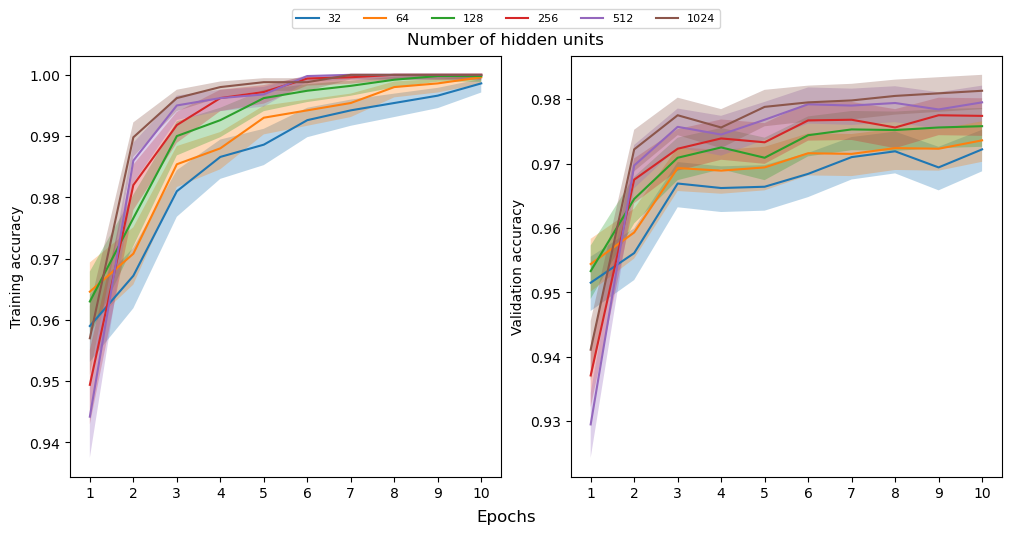

In [27]:
num_rows = 1
num_cols = 2
fig, axes = plt.subplots(num_rows, num_cols, layout="constrained", figsize=(5.0 * num_cols, 5.0 * num_rows))

hidden_dim = 32

for width in [1, 2, 4, 8, 16, 32]:
    model = MLP(
        in_dim=in_dim,
        out_dim=out_dim,
        hidden_dims=[hidden_dim * width],
        activation_cls=ReLU,
        rng=np.random.default_rng(seed),
    )
    opt = Adam(parameters=model.parameters(), lr=0.005)

    trainer = Trainer(
        model=model,
        optimizer=opt,
        update_rule=make_supervised_update_rule(
            pred_loss=CrossEntropyLossWithLogits(),
        ),
        metric=lambda preds, targets, *args: accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        epochs=10,
        batch_size=100,
    ).fit(x_tr, y_tr, x_val, y_val)

    print("Num. hidden units: {} - Num. params: {}".format(
        width * hidden_dim,
        sum([np.prod(param.data.shape) for param in trainer.model.parameters()]).item(),
    ))

    metric = np.array(trainer.history["train_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[0].plot(
        x_range,
        np.mean(metric, axis=-1),
        label=hidden_dim * width
    )
    axes[0].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array(trainer.history["val_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[1].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[1].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

axes[0].set_xticks(x_range)
axes[0].set_ylabel("Training accuracy")
axes[1].set_xticks(x_range)
axes[1].set_ylabel("Validation accuracy")

fig.suptitle("Number of hidden units")
fig.supxlabel("Epochs")
fig.legend(
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=6,
    borderaxespad=0.0,
    frameon=True,
    fontsize="8",
)

### Model architecture experiment

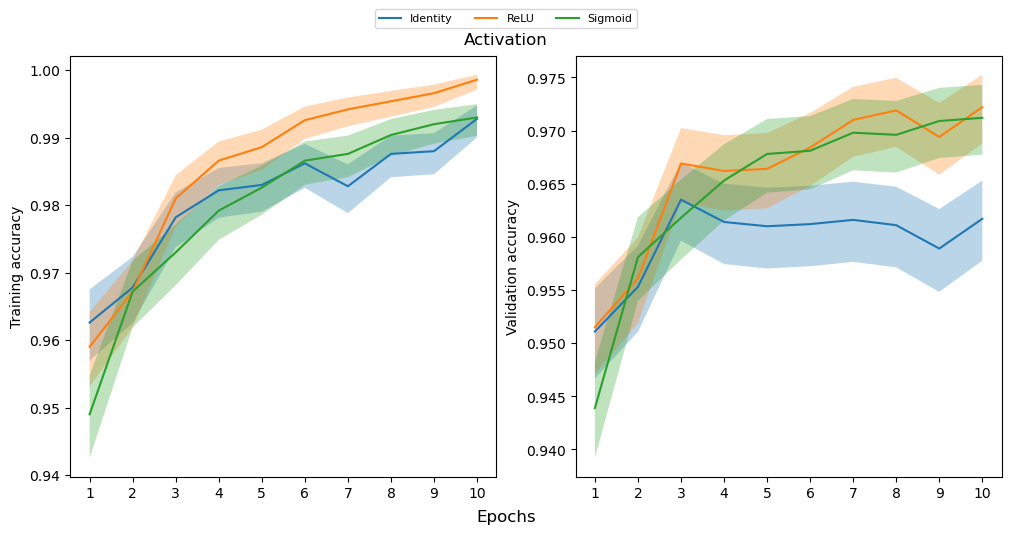

In [28]:
num_rows = 1
num_cols = 2
fig, axes = plt.subplots(num_rows, num_cols, layout="constrained", figsize=(5.0 * num_cols, 5.0 * num_rows))

for act_cls in [
    Identity,
    ReLU,
    Sigmoid,
]:
    model = MLP(
        in_dim=in_dim,
        out_dim=out_dim,
        hidden_dims=[hidden_dim],
        activation_cls=act_cls,
        rng=np.random.default_rng(seed),
    )
    opt = Adam(parameters=model.parameters(), lr=0.005)

    trainer = Trainer(
        model=model,
        optimizer=opt,
        update_rule=make_supervised_update_rule(
            pred_loss=CrossEntropyLossWithLogits(),
        ),
        metric=lambda preds, targets, *args: accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        epochs=10,
        batch_size=100,
    ).fit(x_tr, y_tr, x_val, y_val)

    metric = np.array(trainer.history["train_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[0].plot(
        x_range,
        np.mean(metric, axis=-1),
        label=act_cls.__name__
    )
    axes[0].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array(trainer.history["val_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[1].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[1].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

axes[0].set_xticks(x_range)
axes[0].set_ylabel("Training accuracy")
axes[1].set_xticks(x_range)
axes[1].set_ylabel("Validation accuracy")

fig.suptitle("Activation")
fig.supxlabel("Epochs")
fig.legend(
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=4,
    borderaxespad=0.0,
    frameon=True,
    fontsize="8",
)

Model: MLP--Num. of parameters: 27397
Model: MLPWithSkipConnection--Num. of parameters: 27397


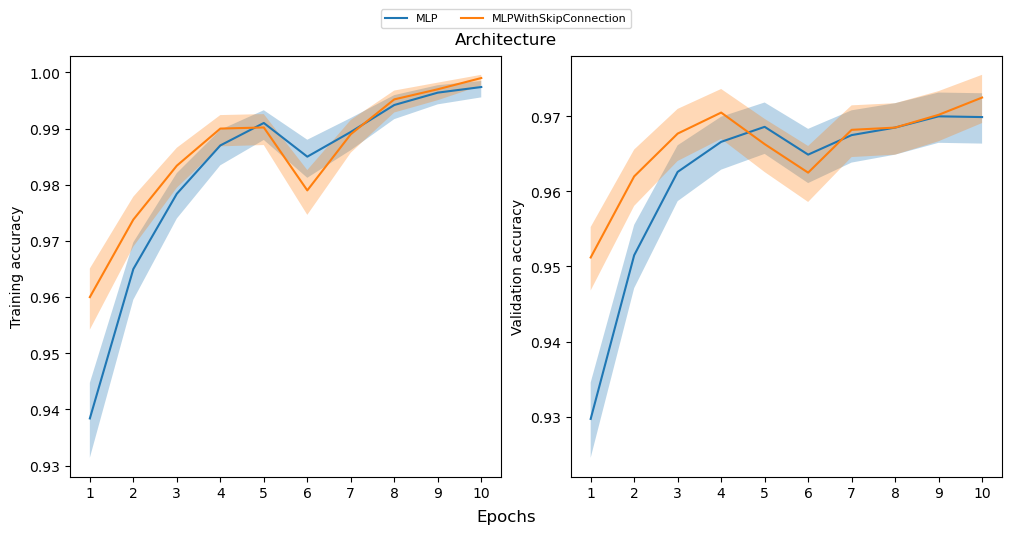

In [29]:
num_rows = 1
num_cols = 2
fig, axes = plt.subplots(num_rows, num_cols, layout="constrained", figsize=(5.0 * num_cols, 5.0 * num_rows))

for model in [
    MLP(
        in_dim=in_dim,
        out_dim=out_dim,
        hidden_dims=[hidden_dim, hidden_dim, hidden_dim],
        activation_cls=ReLU,
        rng=np.random.default_rng(seed),
    ),
    MLPWithSkipConnection(
        in_dim=in_dim,
        out_dim=out_dim,
        hidden_dims=[hidden_dim],
        activation_cls=ReLU,
        rng=np.random.default_rng(seed),
    ),
]:
    print("Model: {}--Num. of parameters: {}".format(
        type(model).__name__,
        np.sum([np.prod(param.data.shape) for param in model.parameters()])
    ))
    opt = Adam(parameters=model.parameters(), lr=0.005)

    trainer = Trainer(
        model=model,
        optimizer=opt,
        update_rule=make_supervised_update_rule(
            pred_loss=CrossEntropyLossWithLogits(),
        ),
        metric=lambda preds, targets, *args: accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        epochs=10,
        batch_size=100,
    ).fit(x_tr, y_tr, x_val, y_val)

    metric = np.array(trainer.history["train_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[0].plot(
        x_range,
        np.mean(metric, axis=-1),
        label=type(model).__name__
    )
    axes[0].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array(trainer.history["val_metric"])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[1].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[1].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

axes[0].set_xticks(x_range)
axes[0].set_ylabel("Training accuracy")
axes[1].set_xticks(x_range)
axes[1].set_ylabel("Validation accuracy")

fig.suptitle("Architecture")
fig.supxlabel("Epochs")
fig.legend(
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=4,
    borderaxespad=0.0,
    frameon=True,
    fontsize="8",
)

## BCE vs MSE

In [30]:
repr_idxes = []
for class_i in range(out_dim):
    repr_idxes.append(np.where(y_val == class_i)[0][0])

In [31]:
model = SupervisedAutoencoder(
    MLP(in_dim=in_dim, out_dim=hidden_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 1)),
    MLP(in_dim=hidden_dim, out_dim=in_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 2)),
    MLP(in_dim=hidden_dim, out_dim=out_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 3)),
)

beta = 1.0
opt = Adam(parameters=model.parameters(), lr=0.005)

mse_trainer = Trainer(
    model=model,
    optimizer=opt,
    update_rule=make_sae_update_rule(
        beta=beta,
        pred_loss=CrossEntropyLossWithLogits(),
        recon_loss=SquaredLoss(),
    ),
    metric=lambda preds, targets, inputs: {
        "accuracy": accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        "pixel_distance": np.mean(np.abs(preds["reconstruction"] - inputs), axis=-1),
    },
    epochs=20,
    batch_size=100,
).fit(x_tr, y_tr, x_val, y_val)

In [32]:
model = SupervisedAutoencoder(
    MLP(in_dim=in_dim, out_dim=hidden_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 1)),
    MLP(in_dim=hidden_dim, out_dim=in_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 2)),
    MLP(in_dim=hidden_dim, out_dim=out_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 3)),
)

beta = 1.0
opt = Adam(parameters=model.parameters(), lr=0.005)

bce_trainer = Trainer(
    model=model,
    optimizer=opt,
    update_rule=make_sae_update_rule(
        beta=beta,
        pred_loss=CrossEntropyLossWithLogits(),
        recon_loss=BinaryCrossEntropyLossWithLogits(),
    ),
    metric=lambda preds, targets, inputs: {
        "accuracy": accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        "pixel_distance": np.mean(np.abs(Sigmoid().forward(preds["reconstruction"]) - inputs), axis=-1),
    },
    epochs=20,
    batch_size=100,
).fit(x_tr, y_tr, x_val, y_val)

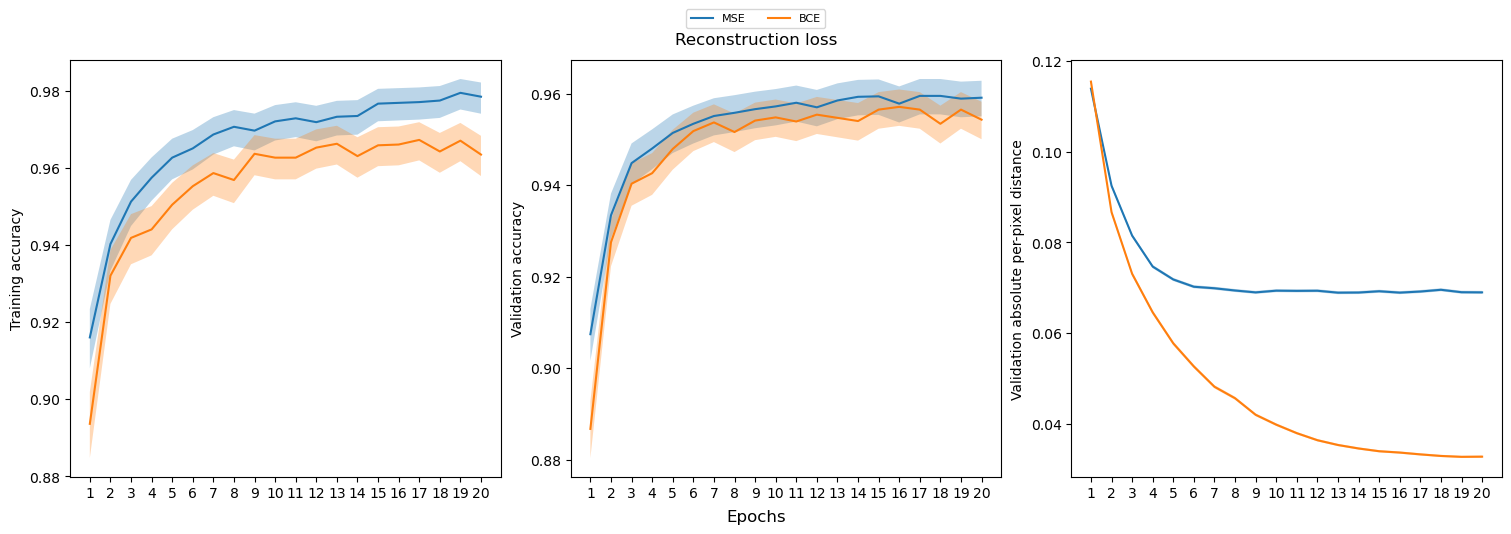

In [33]:
num_rows = 1
num_cols = 3
fig, axes = plt.subplots(num_rows, num_cols, layout="constrained", figsize=(5.0 * num_cols, 5.0 * num_rows))

for name, trainer in zip(["MSE", "BCE"], [mse_trainer, bce_trainer]):
    metric = np.array([metric["accuracy"] for metric in trainer.history["train_metric"]])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[0].plot(
        x_range,
        np.mean(metric, axis=-1),
        label=name
    )
    axes[0].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array([metric["accuracy"] for metric in trainer.history["val_metric"]])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[1].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[1].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array([metric["pixel_distance"] for metric in trainer.history["val_metric"]])
    x_range = np.arange(len(metric)) + 1
    cis = compute_student_t_ci(metric.shape[1], metric, axis=-1)
    axes[2].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[2].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

axes[0].set_xticks(x_range)
axes[0].set_ylabel("Training accuracy")
axes[1].set_xticks(x_range)
axes[1].set_ylabel("Validation accuracy")
axes[2].set_xticks(x_range)
axes[2].set_ylabel("Validation absolute per-pixel distance")

fig.suptitle("Reconstruction loss")
fig.supxlabel("Epochs")
fig.legend(
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=4,
    borderaxespad=0.0,
    frameon=True,
    fontsize="8",
)

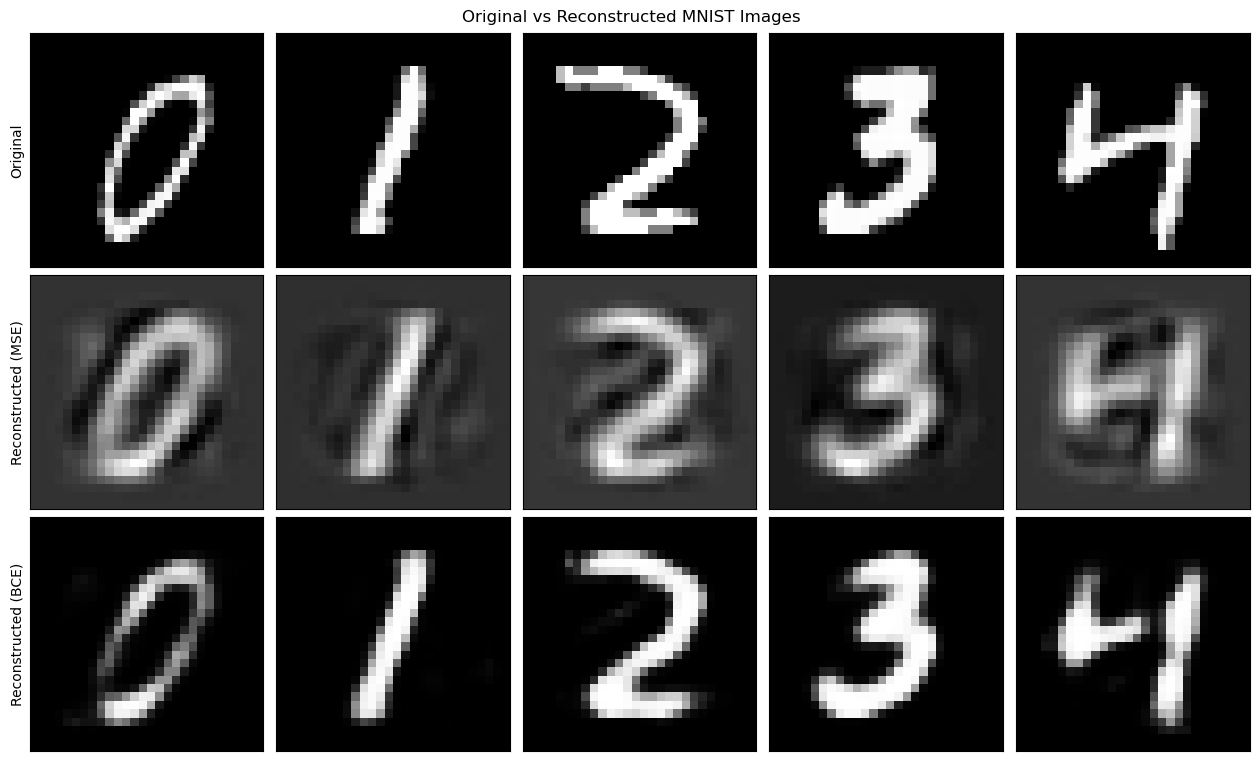

In [34]:
num_rows = 3
num_cols = len(repr_idxes)
fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2.5, num_rows * 2.5), layout="constrained")

fig.suptitle("Original vs Reconstructed MNIST Images")
mse_img = mse_trainer.model.forward(x_val[repr_idxes])["reconstruction"]
bce_img = Sigmoid().forward(bce_trainer.model.forward(x_val[repr_idxes])["reconstruction"])
for i, img_idx in enumerate(repr_idxes):
    axes[0, i].imshow(x_val[img_idx].reshape(28, 28), cmap='gray')
    axes[1, i].imshow(mse_img[i].reshape(28, 28), cmap='gray')
    axes[2, i].imshow(bce_img[i].reshape(28, 28), cmap='gray')
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed (MSE)")
axes[2, 0].set_ylabel("Reconstructed (BCE)")
plt.savefig("figure2.png")
plt.show()

## Sparse neural network

In [35]:
model = SupervisedAutoencoder(
    MLP(in_dim=in_dim, out_dim=hidden_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 1)),
    MLP(in_dim=hidden_dim, out_dim=in_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 2)),
    MLP(in_dim=hidden_dim, out_dim=out_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 3)),
)
beta = 0.02
opt = AdamL1(parameters=model.parameters(), lr=0.005, lambda_=0.005)

l1_trainer = Trainer(
    model=model,
    optimizer=opt,
    update_rule=make_sae_update_rule(
        beta=beta,
        pred_loss=CrossEntropyLossWithLogits(),
        recon_loss=BinaryCrossEntropyLossWithLogits(),
    ),
    metric=lambda preds, targets, inputs: {
        "accuracy": accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        "pixel_distance": np.mean(np.abs(Sigmoid().forward(preds["reconstruction"]) - inputs), axis=-1),
    },
    epochs=10,
    batch_size=100,
).fit(x_tr, y_tr, x_val, y_val)

In [36]:
model = SupervisedAutoencoder(
    MLP(in_dim=in_dim, out_dim=hidden_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 1)),
    MLP(in_dim=hidden_dim, out_dim=in_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 2)),
    MLP(in_dim=hidden_dim, out_dim=out_dim, hidden_dims=[], activation_cls=Identity, rng=np.random.default_rng(seed + 3)),
)

beta = 0.02
opt = Adam(parameters=model.parameters(), lr=0.005)

unreg_trainer = Trainer(
    model=model,
    optimizer=opt,
    update_rule=make_sae_update_rule(
        beta=beta,
        pred_loss=CrossEntropyLossWithLogits(),
        recon_loss=BinaryCrossEntropyLossWithLogits(),
    ),
    metric=lambda preds, targets, inputs: {
        "accuracy": accuracy(np.argmax(preds["prediction"], axis=-1), targets[:, 0]),
        "pixel_distance": np.mean(np.abs(Sigmoid().forward(preds["reconstruction"]) - inputs), axis=-1),
    },
    epochs=10,
    batch_size=100,
).fit(x_tr, y_tr, x_val, y_val)

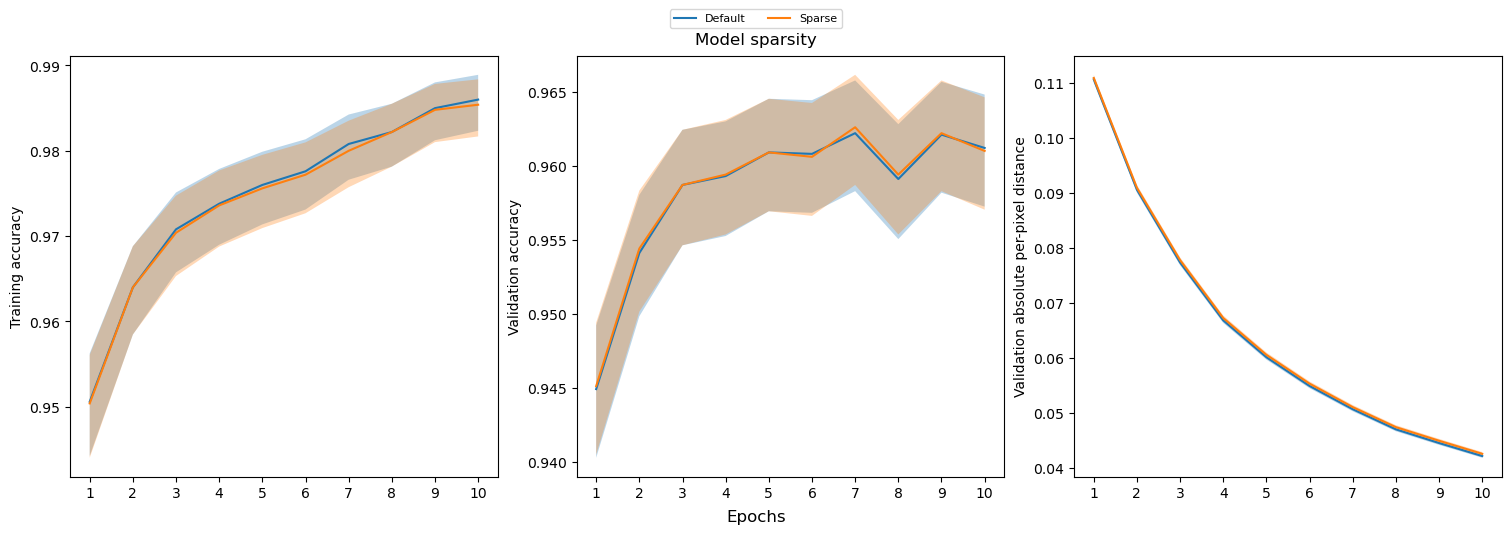

In [37]:
num_rows = 1
num_cols = 3
fig, axes = plt.subplots(num_rows, num_cols, layout="constrained", figsize=(5.0 * num_cols, 5.0 * num_rows))

for name, trainer in zip(["Default", "Sparse"], [unreg_trainer, l1_trainer]):
    metric = np.array([metric["accuracy"] for metric in trainer.history["train_metric"]])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[0].plot(
        x_range,
        np.mean(metric, axis=-1),
        label=name
    )
    axes[0].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array([metric["accuracy"] for metric in trainer.history["val_metric"]])
    x_range = np.arange(len(metric)) + 1
    cis = compute_wilson_ci(metric.shape[1], metric, axis=-1)
    axes[1].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[1].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

    metric = np.array([metric["pixel_distance"] for metric in trainer.history["val_metric"]])
    x_range = np.arange(len(metric)) + 1
    cis = compute_student_t_ci(metric.shape[1], metric, axis=-1)
    axes[2].plot(
        x_range,
        np.mean(metric, axis=-1),
    )
    axes[2].fill_between(
        x_range,
        cis[0],
        cis[1],
        alpha=0.3,
    )

axes[0].set_xticks(x_range)
axes[0].set_ylabel("Training accuracy")
axes[1].set_xticks(x_range)
axes[1].set_ylabel("Validation accuracy")
axes[2].set_xticks(x_range)
axes[2].set_ylabel("Validation absolute per-pixel distance")

fig.suptitle("Model sparsity")
fig.supxlabel("Epochs")
fig.legend(
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=4,
    borderaxespad=0.0,
    frameon=True,
    fontsize="8",
)

In [38]:
zero_threshold = 5e-5

In [39]:
print("L1 model")
for name, param in l1_trainer.model.named_parameters().items():
    print("Layer: {}--% of near-zero weights: {:.2f}% ({}/{})".format(
        name,
        100 * np.sum(np.abs(param.data) < zero_threshold) / np.prod(param.data.shape),
        np.sum(np.abs(param.data) < zero_threshold),
        np.prod(param.data.shape),
    ))

L1 model
Layer: encoder.mlp.layer.0_W--% of near-zero weights: 20.42% (5124/25088)
Layer: encoder.mlp.layer.0_b--% of near-zero weights: 0.00% (0/32)
Layer: decoder.mlp.layer.0_W--% of near-zero weights: 0.10% (26/25088)
Layer: decoder.mlp.layer.0_b--% of near-zero weights: 0.00% (0/784)
Layer: predictor.mlp.layer.0_W--% of near-zero weights: 0.00% (0/160)
Layer: predictor.mlp.layer.0_b--% of near-zero weights: 0.00% (0/5)


In [40]:
print("Unregularized model")
for name, param in unreg_trainer.model.named_parameters().items():
    print("Layer: {}--% of near-zero weights: {:.2f}% ({}/{})".format(
        name,
        100 * np.sum(np.abs(param.data) < zero_threshold) / np.prod(param.data.shape),
        np.sum(np.abs(param.data) < zero_threshold),
        np.prod(param.data.shape),
    ))

Unregularized model
Layer: encoder.mlp.layer.0_W--% of near-zero weights: 0.28% (70/25088)
Layer: encoder.mlp.layer.0_b--% of near-zero weights: 0.00% (0/32)
Layer: decoder.mlp.layer.0_W--% of near-zero weights: 0.02% (6/25088)
Layer: decoder.mlp.layer.0_b--% of near-zero weights: 0.00% (0/784)
Layer: predictor.mlp.layer.0_W--% of near-zero weights: 0.00% (0/160)
Layer: predictor.mlp.layer.0_b--% of near-zero weights: 0.00% (0/5)


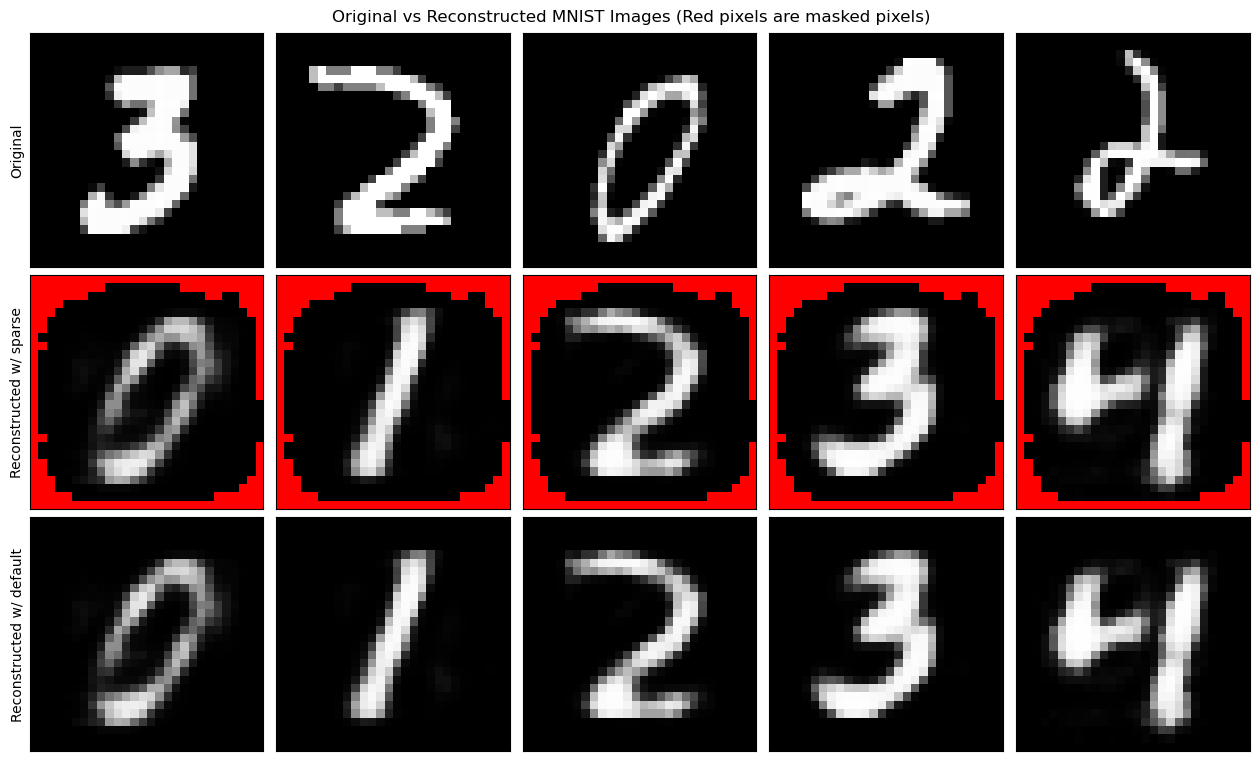

In [41]:
num_rows = 3
num_cols = len(repr_idxes)
fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2.5, num_rows * 2.5), layout="constrained")

fig.suptitle("Original vs Reconstructed MNIST Images (Red pixels are masked pixels)")
l1_masked_pixels = np.sum(np.abs(l1_trainer.model.named_parameters()["encoder.mlp.layer.0_W"].data) <= zero_threshold, axis=-1) == hidden_dim
unreg_masked_pixels = np.sum(np.abs(unreg_trainer.model.named_parameters()["encoder.mlp.layer.0_W"].data) <= zero_threshold, axis=-1) == hidden_dim
l1_img = Sigmoid().forward(l1_trainer.model.forward(x_val[repr_idxes])["reconstruction"])
unreg_img = Sigmoid().forward(unreg_trainer.model.forward(x_val[repr_idxes])["reconstruction"])
for i, img_idx in enumerate(repr_idxes):
    axes[0, i].imshow(np.repeat(x_val[i].reshape(28, 28, 1), repeats=3, axis=-1))

    curr_img = np.repeat(l1_img[i].reshape(28, 28, 1), repeats=3, axis=-1)
    curr_img[l1_masked_pixels.reshape((28, 28))] = (1, 0, 0)
    axes[1, i].imshow(curr_img)

    curr_img = np.repeat(unreg_img[i].reshape(28, 28, 1), repeats=3, axis=-1)
    curr_img[unreg_masked_pixels.reshape((28, 28))] = (1, 0, 0)
    axes[2, i].imshow(curr_img)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed w/ sparse")
axes[2, 0].set_ylabel("Reconstructed w/ default")
plt.savefig("figure3.png")
plt.show()